# ACF with different highpass filter steepness

Load the raw ABES data of shot 20250409.046, apply Butterworth highpass filters at a
**fixed cutoff frequency** (same design as in `filter.ipynb`) while **sweeping the
steepness**, and compare the resulting autocorrelation functions.

The unfiltered (raw) signal is carried through the whole comparison as a reference,
plotted as a black dashed curve. Its DC component is removed before the ACF, otherwise
the ACF would be completely dominated by the mean level of the signal. The same mean
removal is applied to every series, so all of them are treated identically (for the
highpassed ones it is a no-op, their mean is already ~0).

The last section plots the frequency response of the swept filters.

In [32]:
import sys
sys.path.append('/home/smarci/python_libs')

import flap
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import signal
from poloidal_flow import CorrelationConfig, CorrelationAnalysis

In [33]:
defl0 = flap.load('../pickled_shot_data/20250409.046_raw_defl0.pkl')
defl1 = flap.load('../pickled_shot_data/20250409.046_raw_defl1.pkl')

## Filtering

Fixed cutoff frequency, swept steepness. In FLAP the steepness is the width of the
transition band as a fraction of the cutoff frequency, so for a highpass

    f_passband = f_low * (1 + steepness / 2)
    f_stopband = f_low * (1 - steepness / 2)

and the filter order follows from these together with `Loss` and `Attenuation`.

Note the sampling rate: these signals are already background-subtracted, and
`background_subtraction()` averages each chopper period down to a single sample, so the
effective sampling rate is the chopper rate for one deflection state (50 kHz here),
*not* the 2 MHz APDCAM rate. With a 500 Hz cutoff at 2% of Nyquist the transfer-function
coefficients are well conditioned up to about 18th order, i.e. down to steepness ~0.3.
Below that the order explodes (27th at steepness 0.2, 53rd at 0.1) and the `ba` form
FLAP uses does break down. The sweep below stays well inside the safe range; the
frequency response section at the end prints the actual order and the realised passband
gain for each setting.

The time window is sliced out with some padding first, so that the filter transient at
the window edges is cut away afterwards.

In [34]:
t = 6.5
twindow = 1.0
pad = 0.05

# Fixed filter parameters
F_LOW = 500      # Hz, cutoff frequency
LOSS = 1         # dB, max passband loss
ATTENUATION = 40  # dB, min stopband attenuation

RAW = 'raw'
steepnesses = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75]
series = [RAW] + steepnesses  # RAW = unfiltered reference

defl0_pad = defl0.slice_data(slicing={'Time': flap.Intervals(t - pad, t + twindow + pad)})
defl1_pad = defl1.slice_data(slicing={'Time': flap.Intervals(t - pad, t + twindow + pad)})

In [35]:
def highpass(data, steepness):
    """Butterworth highpass with the design used in filter.ipynb, at fixed F_LOW."""
    return data.filter_data(
        coordinate='Time',
        options={
            'Design': 'Butterworth',
            'Type': 'Highpass',
            'f_low': F_LOW,
            'Steepness': steepness,
            'Loss': LOSS,
            'Attenuation': ATTENUATION
        }
    )


def window(data):
    """Cut to the analysis window and remove the DC component."""
    return data.slice_data(
        slicing={'Time': flap.Intervals(t, t + twindow)}
    ).detrend(
        coordinate='Time', options={'Trend removal': 'Mean'}
    )


filtered0 = {RAW: window(defl0_pad)}
filtered1 = {RAW: window(defl1_pad)}

for steep in steepnesses:
    filtered0[steep] = window(highpass(defl0_pad, steep))
    filtered1[steep] = window(highpass(defl1_pad, steep))
    print(f'steepness {steep} done')

steepness 0.5 done
steepness 0.75 done
steepness 1.0 done
steepness 1.25 done
steepness 1.5 done
steepness 1.75 done


## ACF calculation

In [36]:
xconfig = CorrelationConfig(
    'parabola', 1,
    xcorr_interval=100,
    xcorr_time_lag_interval=(-500e-6, 500e-6)
)

anal = CorrelationAnalysis(filtered0[RAW], filtered1[RAW], xconfig)

In [37]:
channels = np.arange(1, 41)

# acf0[key] / acf1[key]: (n_channel, n_lag) arrays, key is RAW or a steepness value
acf0 = {}
acf1 = {}
time_lag_axis = None

for key in series:
    a0_list = []
    a1_list = []

    for ch in channels:
        d0 = filtered0[key].slice_data(slicing={'Channel number': ch})
        d1 = filtered1[key].slice_data(slicing={'Channel number': ch})

        a0 = anal.acf_window_single(d0)
        a1 = anal.acf_window_single(d1)

        if time_lag_axis is None:
            time_lag_axis = a0.coordinate('Time lag')[0] * 1e6  # us

        a0_list.append(a0.data)
        a1_list.append(a1.data)

    acf0[key] = np.array(a0_list)
    acf1[key] = np.array(a1_list)
    print(f'{key} done')

Interval 1/100
Interval 2/100
Interval 3/100
Interval 4/100
Interval 5/100
Interval 6/100
Interval 7/100
Interval 8/100
Interval 9/100
Interval 10/100
Interval 11/100
Interval 12/100
Interval 13/100
Interval 14/100
Interval 15/100
Interval 16/100
Interval 17/100
Interval 18/100
Interval 19/100
Interval 20/100
Interval 21/100
Interval 22/100
Interval 23/100
Interval 24/100
Interval 25/100
Interval 26/100
Interval 27/100
Interval 28/100
Interval 29/100
Interval 30/100
Interval 31/100
Interval 32/100
Interval 33/100
Interval 34/100
Interval 35/100
Interval 36/100
Interval 37/100
Interval 38/100
Interval 39/100
Interval 40/100
Interval 41/100
Interval 42/100
Interval 43/100
Interval 44/100
Interval 45/100
Interval 46/100
Interval 47/100
Interval 48/100
Interval 49/100
Interval 50/100
Interval 51/100
Interval 52/100
Interval 53/100
Interval 54/100
Interval 55/100
Interval 56/100
Interval 57/100
Interval 58/100
Interval 59/100
Interval 60/100
Interval 61/100
Interval 62/100
Interval 63/100
I

## Comparison for selected channels

One panel per channel, one curve per highpass cutoff frequency, plus the unfiltered
signal in black dashed.

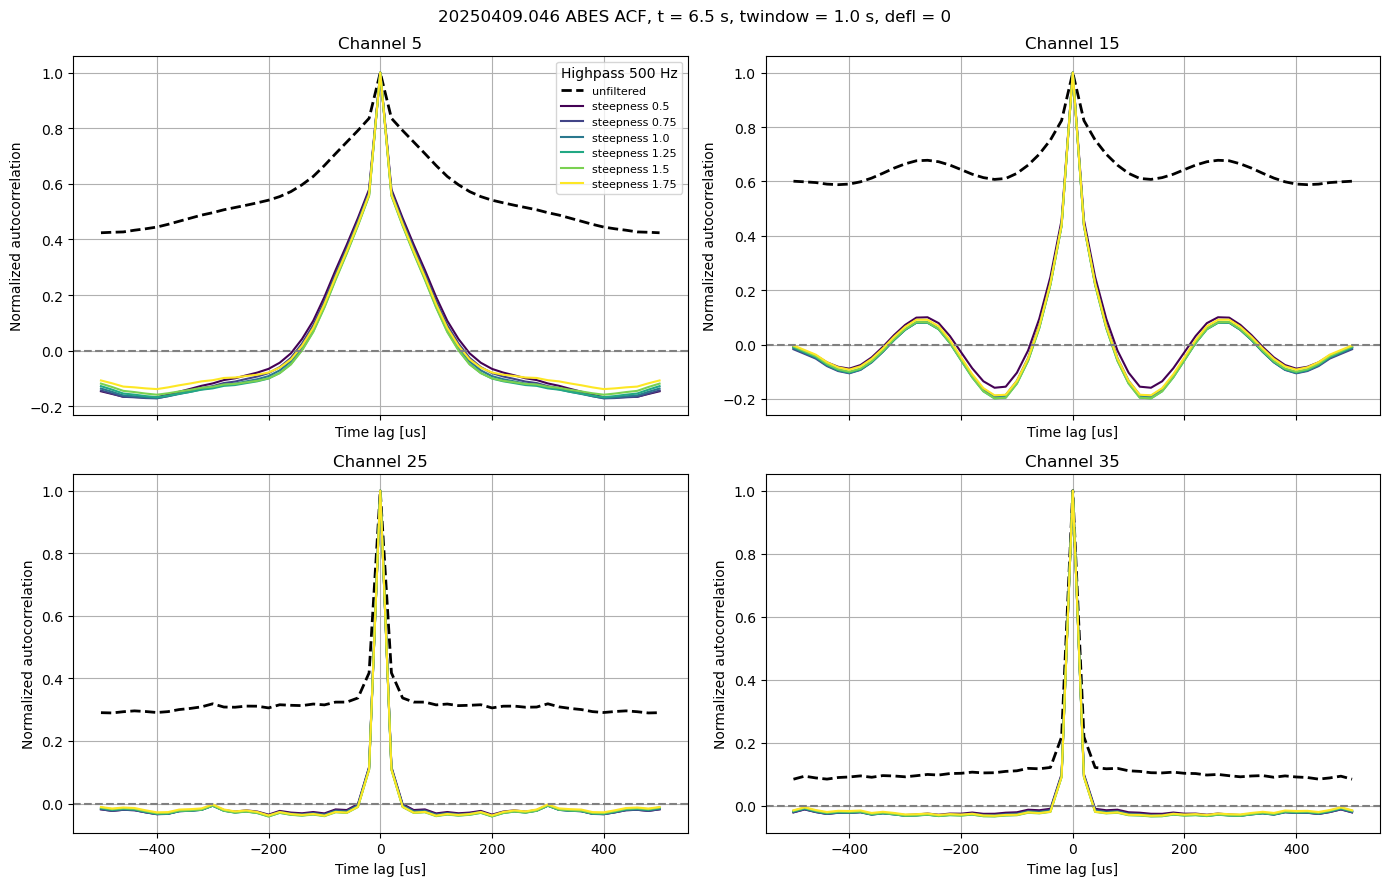

In [38]:
plot_channels = [5, 15, 25, 35]

norm = mpl.colors.Normalize(vmin=min(steepnesses), vmax=max(steepnesses))
cmap = mpl.colormaps['viridis']


def series_style(key):
    """Colour / linestyle / label for one series; the unfiltered one is black and dashed."""
    if key == RAW:
        return dict(color='k', ls='--', lw=2, label='unfiltered')
    return dict(color=cmap(norm(key)), ls='-', lw=1.5, label=f'steepness {key}')


def plot_channel_comparison(acf_dict, defl_label):
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)

    for ax, ch in zip(axes.ravel(), plot_channels):
        i = int(np.where(channels == ch)[0][0])
        for key in series:
            ax.plot(time_lag_axis, acf_dict[key][i], **series_style(key))
        ax.axhline(0, ls='--', lw=1.5, c='gray')
        ax.set_title(f'Channel {ch}')
        ax.set_xlabel('Time lag [us]')
        ax.set_ylabel('Normalized autocorrelation')
        ax.grid()

    axes[0, 0].legend(title=f'Highpass {F_LOW} Hz', fontsize=8)
    fig.suptitle(
        f'20250409.046 ABES ACF, t = {t} s, twindow = {twindow} s, defl = {defl_label}'
    )
    fig.tight_layout()
    return fig, axes


plot_channel_comparison(acf0, 0);

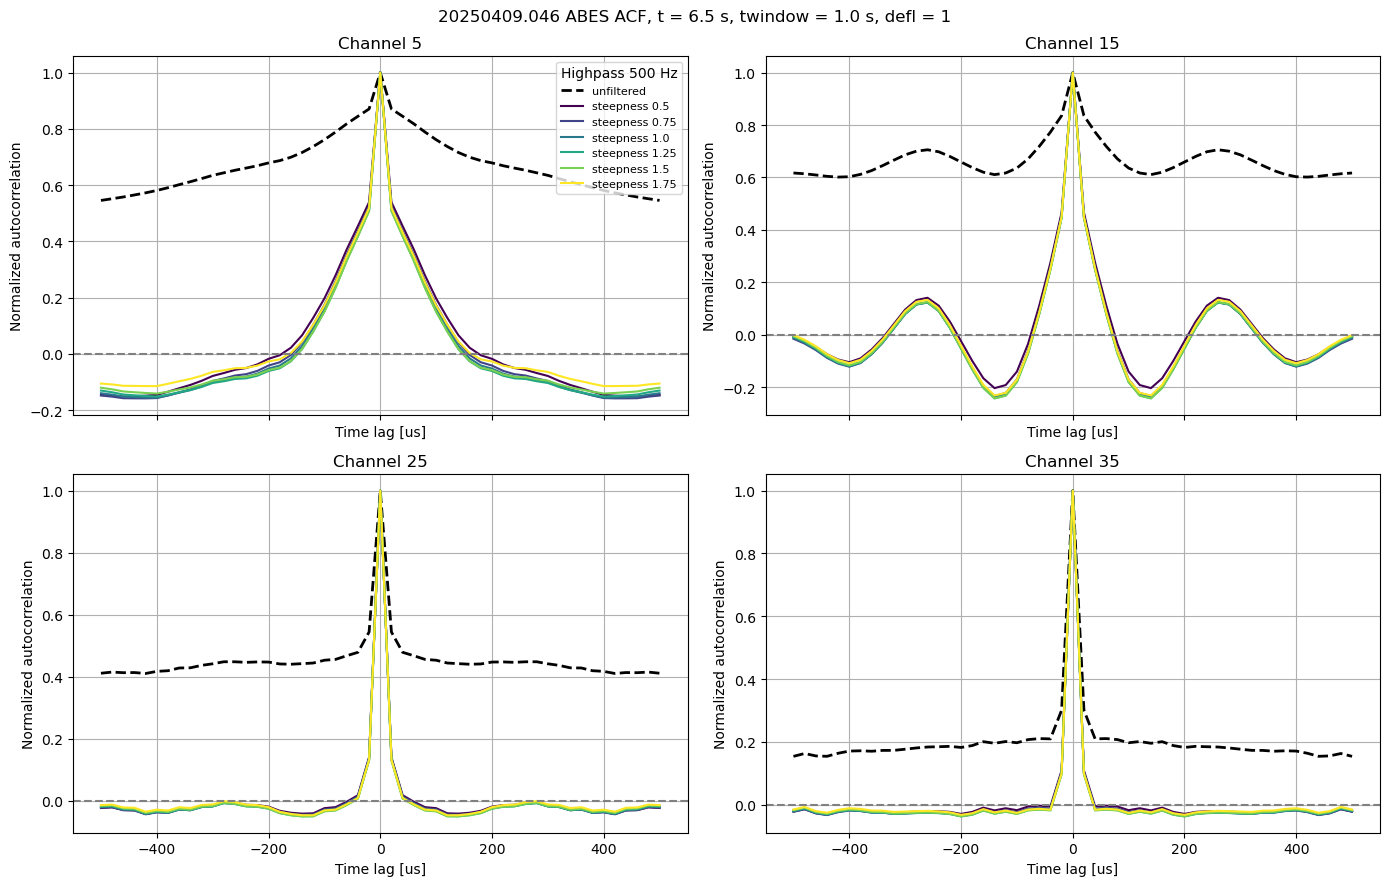

In [39]:
plot_channel_comparison(acf1, 1);

## All channels, one panel per filter

The first panel is the unfiltered signal.

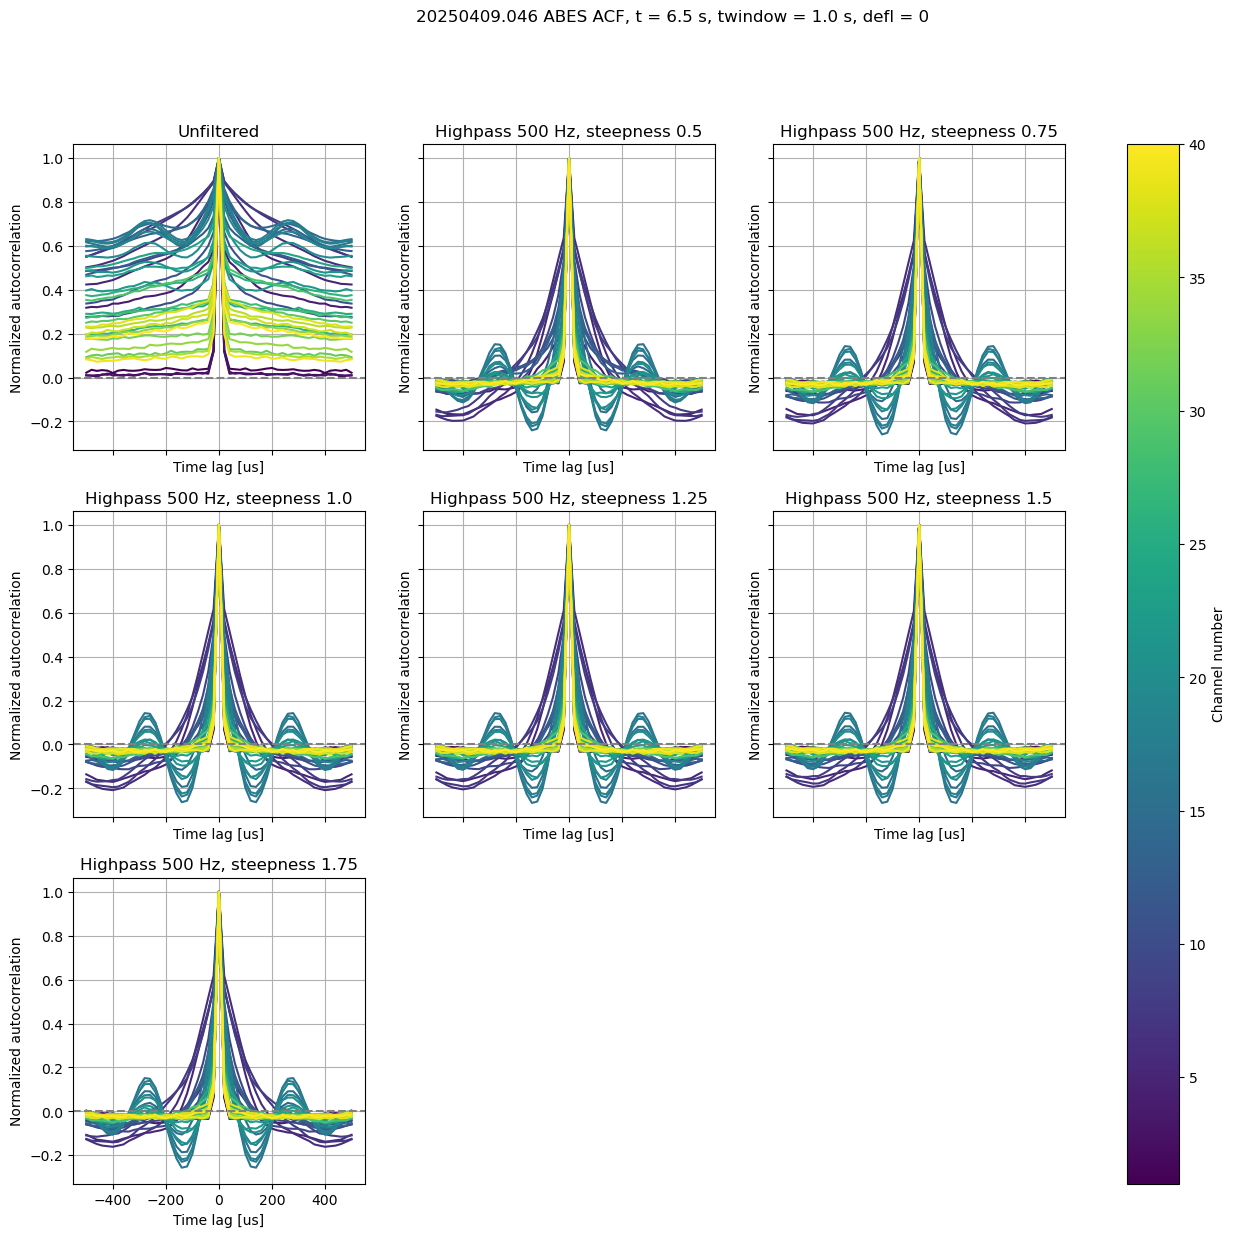

In [40]:
ch_norm = mpl.colors.Normalize(vmin=channels.min(), vmax=channels.max())
ch_sm = mpl.cm.ScalarMappable(norm=ch_norm, cmap=cmap)


def plot_all_channels(acf_dict, defl_label):
    ncols = 3
    nrows = int(np.ceil(len(series) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.5 * nrows), sharex=True, sharey=True)

    for ax, key in zip(axes.ravel(), series):
        for i, ch in enumerate(channels):
            ax.plot(time_lag_axis, acf_dict[key][i], color=cmap(ch_norm(ch)))
        ax.axhline(0, ls='--', lw=1.5, c='gray')
        ax.set_title('Unfiltered' if key == RAW else f'Highpass {F_LOW} Hz, steepness {key}')
        ax.set_xlabel('Time lag [us]')
        ax.set_ylabel('Normalized autocorrelation')
        ax.grid()

    for ax in axes.ravel()[len(series):]:
        ax.set_visible(False)

    cbar = fig.colorbar(ch_sm, ax=axes.ravel().tolist())
    cbar.set_label('Channel number')
    fig.suptitle(
        f'20250409.046 ABES ACF, t = {t} s, twindow = {twindow} s, defl = {defl_label}'
    )
    return fig, axes


plot_all_channels(acf0, 0);

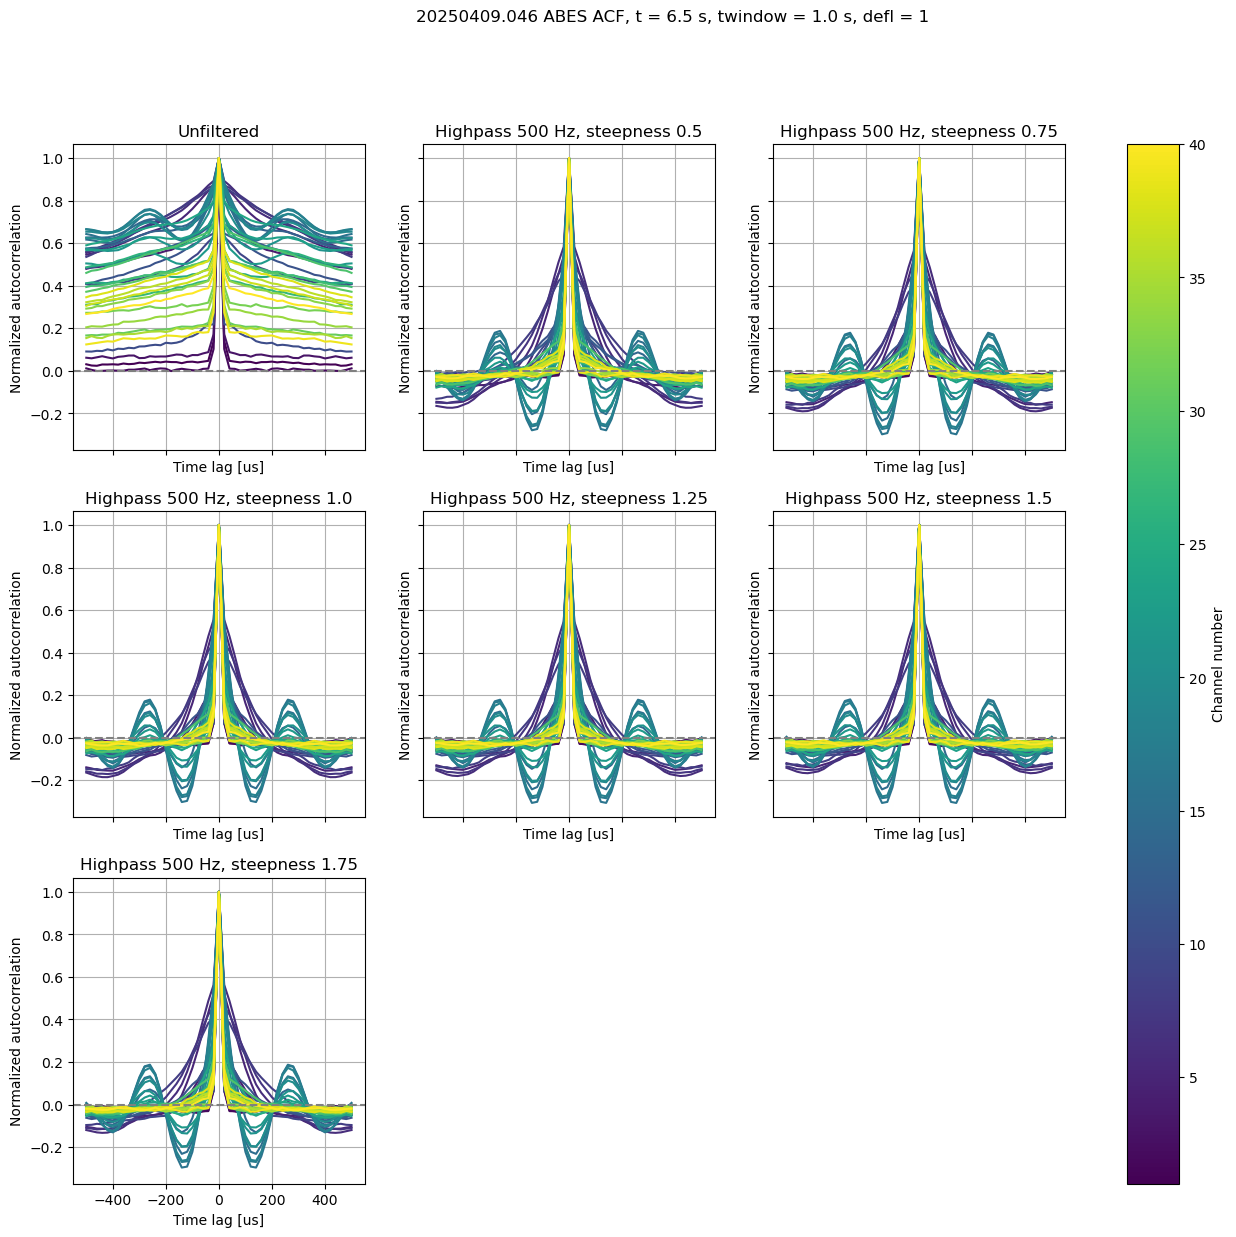

In [41]:
plot_all_channels(acf1, 1);

## ACF width vs. steepness

Quantitative comparison: FWHM of the ACF main peak (first crossing of 0.5 on each side).
Series whose ACF does not drop to 0.5 inside the plotted lag range give `NaN`.

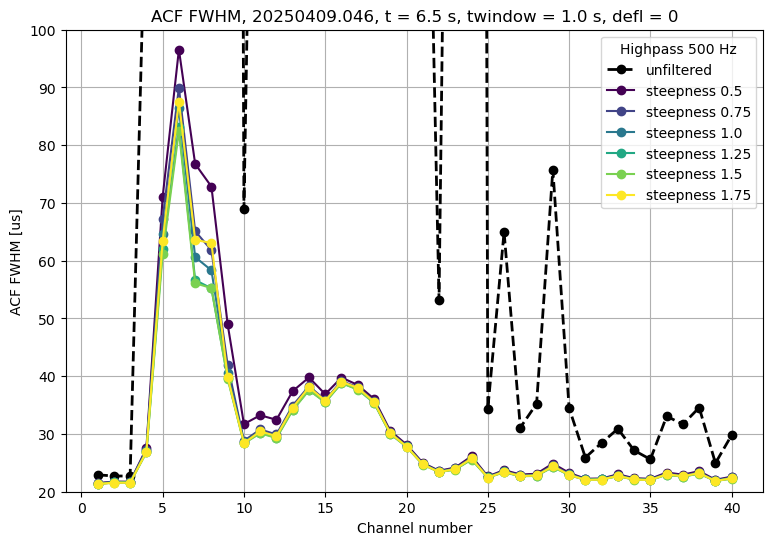

In [42]:
def acf_fwhm(acf, lags):
    """FWHM of the ACF peak at zero lag, by linear interpolation of the 0.5 crossings."""
    i0 = int(np.argmin(np.abs(lags)))

    def crossing(idx_range):
        prev = idx_range[0]
        for i in idx_range[1:]:
            if acf[i] <= 0.5:
                return np.interp(0.5, [acf[i], acf[prev]], [lags[i], lags[prev]])
            prev = i
        return np.nan

    left = crossing(list(range(i0, -1, -1)))
    right = crossing(list(range(i0, len(lags))))
    return right - left


fig, ax = plt.subplots(figsize=(9, 6))

for key in series:
    widths = [acf_fwhm(acf0[key][i], time_lag_axis) for i in range(len(channels))]
    ax.plot(channels, widths, marker='o', **series_style(key))

ax.set_title(f'ACF FWHM, 20250409.046, t = {t} s, twindow = {twindow} s, defl = 0')
ax.set_xlabel('Channel number')
ax.set_ylabel('ACF FWHM [us]')
ax.legend(title=f'Highpass {F_LOW} Hz')

plt.ylim(20, 100)

ax.grid()

## Frequency response of the filters

The filter coefficients are reproduced exactly as FLAP builds them internally in
`DataObject.filter_data` for a highpass:

```python
fn = 1 / dt / 2
wp = (f_low + f_low * steep / 2) / fn
ws = (f_low - f_low * steep / 2) / fn
b, a = scipy.signal.iirdesign(wp, ws, loss, attenuation, ftype=design, output='ba')
```

so the solid curves are the responses actually applied to the data. The dotted curves are
the *same* design realised in second-order-section form, i.e. the numerically robust
reference.

At this sampling rate the two agree: the printed `ba` passband gain is flat to 0.00 dB
for every steepness in the sweep, so the transfer-function form FLAP applies is faithful
to the intended design and the solid and dotted curves lie on top of each other. This is
only true because background subtraction has already decimated the signal to the 50 kHz
chopper rate — at the raw 2 MHz APDCAM rate the same 11th-order design would swing by
tens of dB across the passband and be unusable.

The group delay panel is informative but does not affect the ACF: the autocorrelation
depends on `|H(f)|^2` only, so filter phase cancels. It also cancels in the defl0/defl1
CCF as long as both states get an identical filter.

Sampling frequency: 0.050 MHz
steepness   0.5: order  11, stopband edge  375 Hz, passband edge  625 Hz, ba passband gain -0.00 .. +0.00 dB
steepness  0.75: order   7, stopband edge  312 Hz, passband edge  688 Hz, ba passband gain -0.00 .. +0.00 dB
steepness   1.0: order   5, stopband edge  250 Hz, passband edge  750 Hz, ba passband gain -0.00 .. +0.00 dB
steepness  1.25: order   4, stopband edge  188 Hz, passband edge  812 Hz, ba passband gain -0.00 .. +0.00 dB
steepness   1.5: order   3, stopband edge  125 Hz, passband edge  875 Hz, ba passband gain -0.00 .. +0.00 dB
steepness  1.75: order   2, stopband edge   62 Hz, passband edge  938 Hz, ba passband gain -0.02 .. +0.00 dB


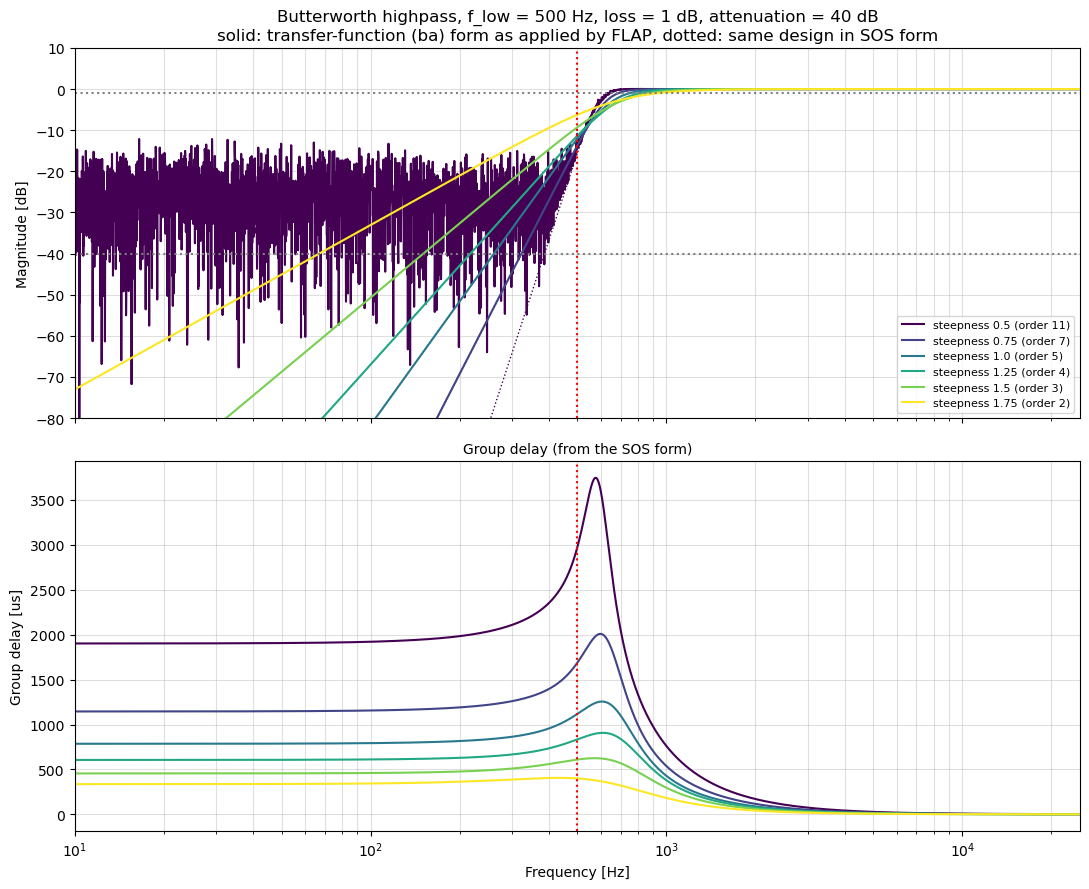

In [43]:
dt = defl0.get_coordinate_object('Time').step[0]
fs = 1 / dt
fn = fs / 2
print(f'Sampling frequency: {fs / 1e6:.3f} MHz')


def highpass_design(steepness, output='ba'):
    """The filter FLAP designs for this highpass setting (output='ba' is what it applies)."""
    wp = (F_LOW + F_LOW * steepness / 2) / fn
    ws = (F_LOW - F_LOW * steepness / 2) / fn
    return signal.iirdesign(wp, ws, LOSS, ATTENUATION, ftype='butter', output=output)


freqs = np.logspace(1, np.log10(fn), 4000)  # Hz

fig, (ax_mag, ax_gd) = plt.subplots(2, 1, figsize=(11, 9), sharex=True)

for steep in steepnesses:
    b, a = highpass_design(steep, output='ba')
    sos = highpass_design(steep, output='sos')
    order = len(a) - 1

    _, h_ba = signal.freqz(b, a, worN=freqs, fs=fs)
    _, h_sos = signal.sosfreqz(sos, worN=freqs, fs=fs)

    # Group delay from the (numerically sound) SOS phase: gd = -dphi/domega
    phase = np.unwrap(np.angle(h_sos))
    gd = -np.gradient(phase, 2 * np.pi * freqs) * 1e6  # us

    style = series_style(steep)
    style['label'] = f'steepness {steep} (order {order})'

    ax_mag.semilogx(freqs, 20 * np.log10(np.abs(h_ba) + 1e-30), **style)
    ax_mag.semilogx(freqs, 20 * np.log10(np.abs(h_sos) + 1e-30),
                    color=style['color'], ls=':', lw=1)
    ax_gd.semilogx(freqs, gd, **style)

    pb = np.abs(h_ba)[freqs > 5 * F_LOW]
    print(f'steepness {steep:>5}: order {order:>3}, '
          f'stopband edge {F_LOW * (1 - steep / 2):>4.0f} Hz, '
          f'passband edge {F_LOW * (1 + steep / 2):>4.0f} Hz, '
          f'ba passband gain {20 * np.log10(pb.min()):+.2f} .. '
          f'{20 * np.log10(pb.max()):+.2f} dB')

for ax in (ax_mag, ax_gd):
    ax.axvline(F_LOW, ls=':', c='r', lw=1.5)
    ax.grid(which='both', alpha=0.4)
    ax.set_xlim(freqs[0], freqs[-1])

ax_mag.axhline(-LOSS, ls=':', c='gray', lw=1.5)
ax_mag.axhline(-ATTENUATION, ls=':', c='gray', lw=1.5)
ax_mag.set_ylim(-80, 10)
ax_mag.set_ylabel('Magnitude [dB]')
ax_mag.set_title(f'Butterworth highpass, f_low = {F_LOW} Hz, '
                 f'loss = {LOSS} dB, attenuation = {ATTENUATION} dB\n'
                 'solid: transfer-function (ba) form as applied by FLAP, '
                 'dotted: same design in SOS form')
ax_mag.legend(fontsize=8, loc='lower right')

ax_gd.set_ylabel('Group delay [us]')
ax_gd.set_xlabel('Frequency [Hz]')
ax_gd.set_title('Group delay (from the SOS form)', fontsize=10)

fig.tight_layout()